# Pokémon card clustering over time
**Question:** Do cards with similar characteristics have similar prices over time?

We group products by their characteristics, then compare monthly ungraded prices from December 2020 through November 2024.

## 1. Load one row per card printing
A base card and its reverse-holo printing are separate products. We use set age, rarity, and printing. Products without required characteristics are left out. Prices are not used to select or fit the clusters.

In [1]:
import pandas as pd
from IPython.display import display, Image
from main import load_data
from longitudinal import OUTPUT, load_products, make_features, compare_k, monthly_prices, describe_clusters, save_results
products = load_products()
print(f'{len(products):,} products')
display(products[['name', 'age_years', 'rarity', 'variant']].head().round(2))

29,877 products


,name,age_years,rarity,variant
0,Corviknight,4.30,Rare Holo,pre-release
1,Alolan Sandslash,7.82,Promo,base
2,Alolan Ninetales,7.82,Promo,base
3,Professor Kukui,7.82,Rare Ultra,base
4,Galarian Sirfetch'd V,4.05,Rare Ultra,base


## 2. Prepare numeric features
K-means uses numeric coordinates and Euclidean distance. Standardize age by subtracting its mean and dividing by its standard deviation, so age measured in years does not overwhelm the other inputs.

Rarity and printing are words, so we convert each category into a 0/1 column. For example, a reverse-holo product has `variant_reverse-holo = 1`. We do not assign arbitrary ranks such as Common=1 and Rare=2.

In [2]:
features = make_features(products)
print('Numeric feature table:', features.shape)
print('Standardized age mean:', round(features.age_years.mean(), 6))
display(features[['age_years', 'variant_base', 'variant_reverse-holo']].head().round(2))

Numeric feature table: (29877, 272)
Standardized age mean: -0.0


,age_years,variant_base,variant_reverse-holo
0,-0.92,0.0,0.0
1,-0.43,1.0,0.0
2,-0.43,1.0,0.0
3,-0.43,1.0,0.0
4,-0.95,1.0,0.0


## 3. K-means and the elbow method
SSE is the sum of squared distances from each point to its assigned center. Lower SSE means points are closer to their centers, but adding clusters generally lowers SSE too. Look for a bend where further clusters provide smaller improvements.

We try K=1 through K=8 on the same products. `n_init=10` tries ten starting arrangements; `random_state=42` makes the run repeatable. `tol=0` avoids stopping early for a small center change. We use K=4 as the project's working choice for describing several groups. It is not automatically the best K, and the elbow may be gradual.

In [3]:
chosen_k = 4
elbow, model = compare_k(features, chosen_k)
products['cluster'] = model.labels_
display(elbow.round(2))

,k,sse
0,1,70472.76
1,2,47199.05
2,3,38923.51
3,4,34511.52
4,5,31930.56
5,6,29707.16
6,7,27752.32
7,8,25819.49


## 4. Describe the clusters
Each product belongs to exactly one cluster (hard, partitional clustering). Cluster numbers are names, not a ranking. A most-common category is not necessarily a majority.

We summarize each group with its number of products, average set age, most common rarity, and most common printing. Age is measured at November 2024, and membership stays fixed throughout the price chart.

In [4]:
display(describe_clusters(products).round(2))

,cluster,products,mean_age_years,most_common_rarity,most_common_printing
0,0,7236,19.84,Common,base
1,1,6865,5.17,Common,reverse-holo
2,2,5021,16.80,Common,reverse-holo
3,3,10755,5.94,Common,base


## 5. Compare prices across all available months
Attach prices only after fitting. For each cluster and month, calculate the median ungraded price and count the products with a price. The median is the middle value, so a few very expensive cards have less influence than they would on a mean.

Keep missing prices missing. Exclude observations before the listed set release month. Plot counts beside prices: a monthly median based on few products is less representative. A rising median can also result from different products being observed, so this chart does not measure the return on a fixed collection of cards.

Removed 560 rows before the listed set release month.


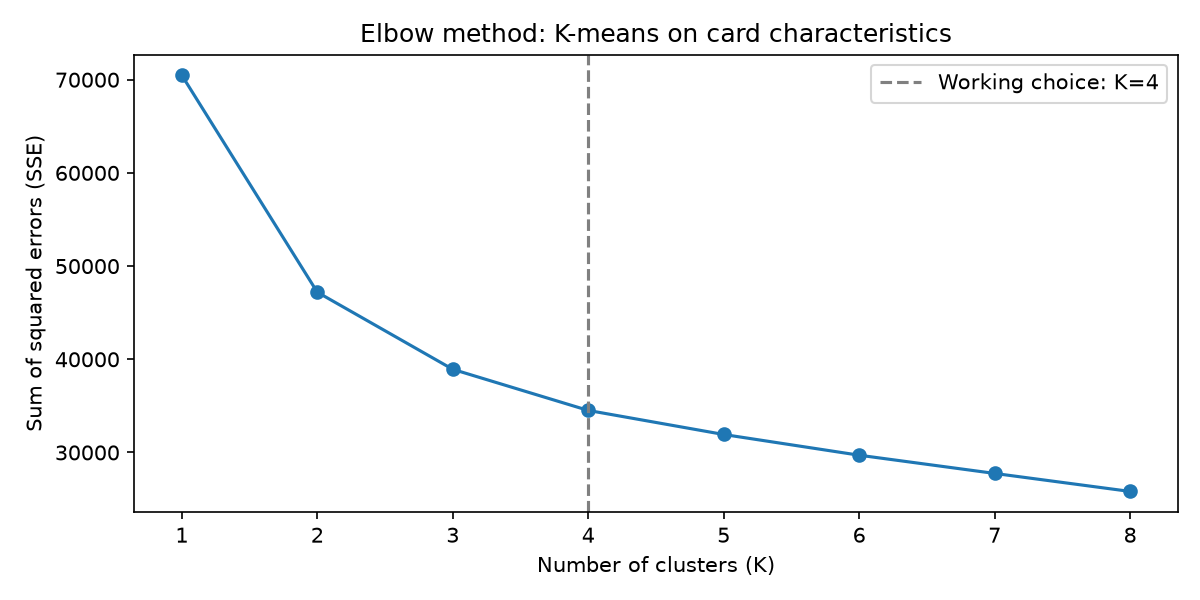

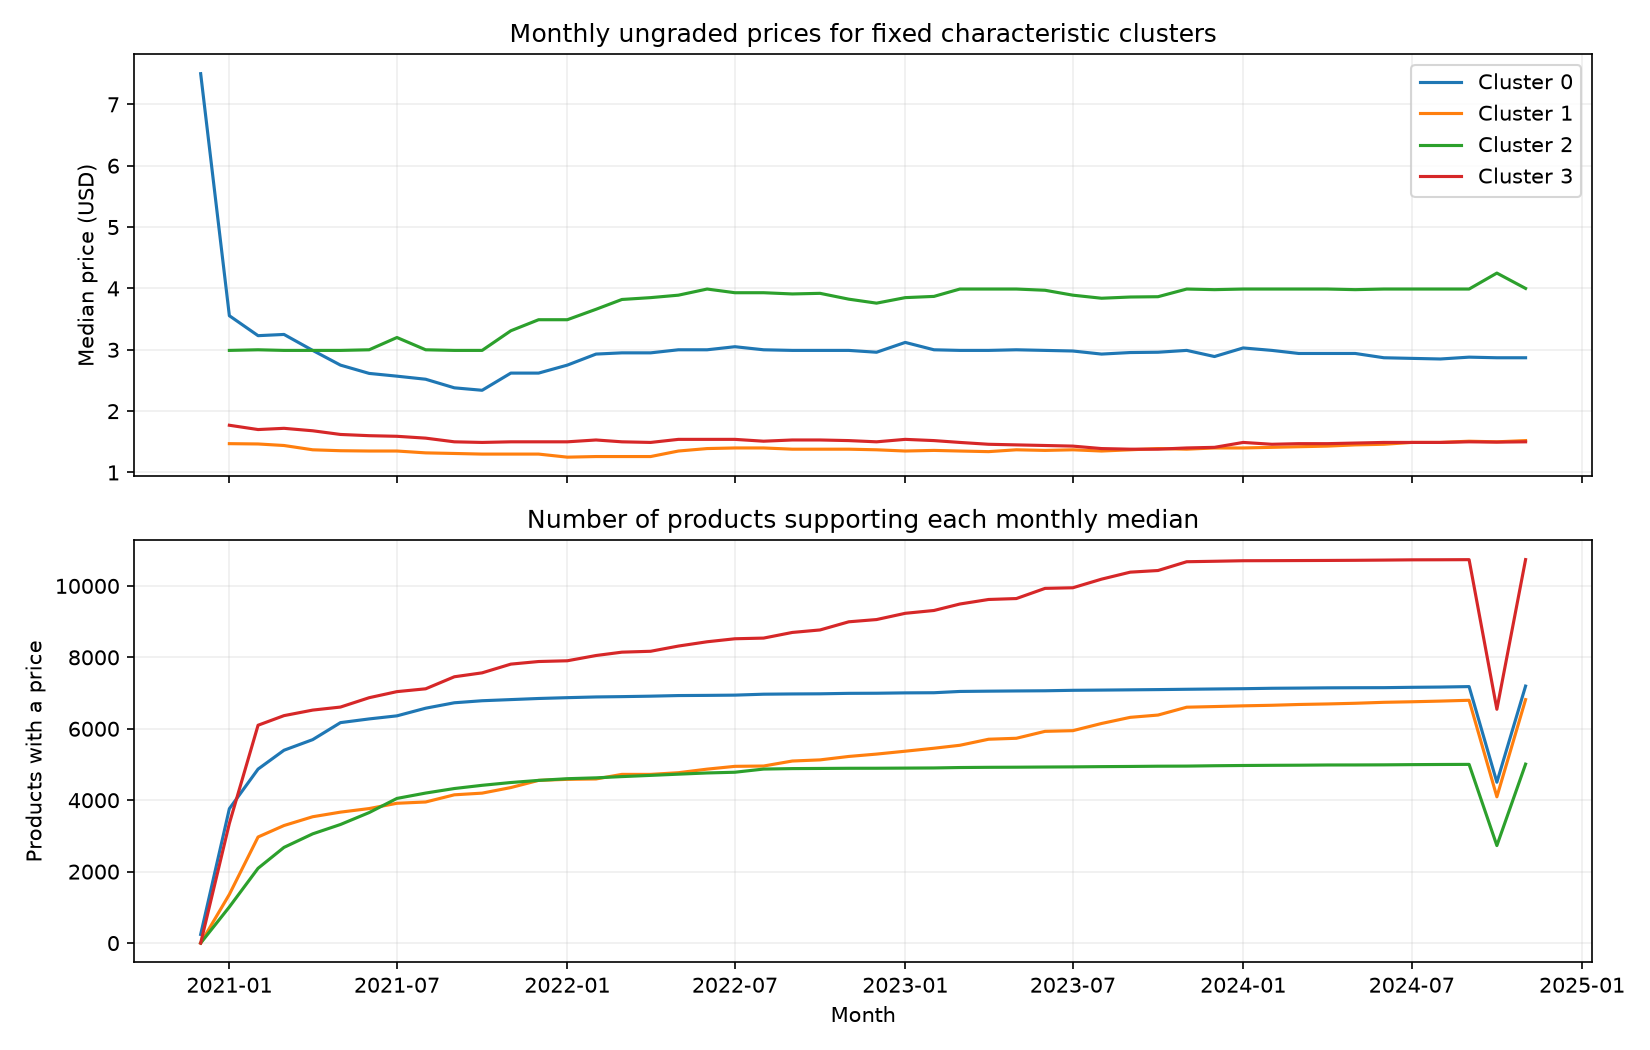

In [5]:
panel = load_data()
monthly = monthly_prices(panel, products)
summary = save_results(products, features, model, elbow, monthly)
display(Image(filename=str(OUTPUT / 'elbow.png')))
display(Image(filename=str(OUTPUT / 'monthly_prices.png')))

## 6. Read the results
The table below shows each group's characteristics and final-month price. Use the full history chart to see whether the price differences persist over time. December 2020 has very few observations, and October 2024 has a noticeable drop in available prices.

In [ ]:
display(summary.round(2))
print('Saved results:', OUTPUT)

,cluster,products,mean_age_years,most_common_rarity,most_common_printing,month,median_price_usd,products_with_price
0,0,7236,19.84,Common,base,2024-11,2.87,7195
1,1,6865,5.17,Common,reverse-holo,2024-11,1.52,6817
2,2,5021,16.80,Common,reverse-holo,2024-11,4.00,5010
3,3,10755,5.94,Common,base,2024-11,1.50,10737


Saved results: /mnt/c/Users/truon/Developer/4334_Datamine/pokemon-tcg-cards-and-prices/results/longitudinal
Original model and more advanced analyses are separate from this class-level notebook.
